# Export example: four things to check in a static copy

This notebook goes with the chapter [Export your notebooks to HTML and PDF](../chapters/export.md).
Each section produces one kind of content that often goes wrong in a static export.
Sections 3 and 4 show the problem first and a fix right after it, so you can compare both in the exported file.

Run *Kernel > Restart & Run All*, save, then follow the chapter to export it.

## 1. An equation

The sample mean and standard deviation of $n$ observations:

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i, \qquad
s = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n} \left(x_i - \bar{x}\right)^2}
$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A fixed seed gives the same numbers on every run.
rng = np.random.default_rng(seed=42)
x = rng.normal(loc=10.0, scale=2.0, size=200)
print(f"mean = {x.mean():.3f}, std = {x.std(ddof=1):.3f}")

mean = 9.939, std = 1.764


## 2. A plot

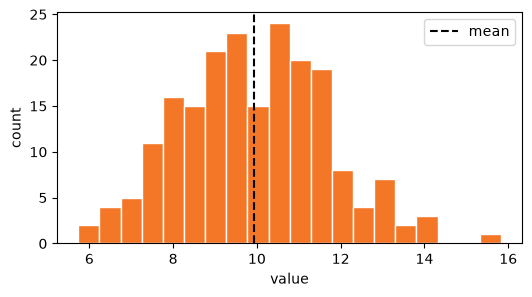

In [2]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(x, bins=20, color="#f37726", edgecolor="white")
ax.axvline(x.mean(), color="black", linestyle="--", label="mean")
ax.set_xlabel("value")
ax.set_ylabel("count")
ax.legend()
plt.show()

## 3. A wide table

Twelve columns are wider than a portrait page.
Check whether the export keeps `sample_12`, the last column.

In [3]:
columns = [f"sample_{i:02d}" for i in range(1, 13)]
runs = [f"run {r}" for r in range(1, 6)]
values = rng.normal(10.0, 2.0, size=(5, 12)).round(2)
summary = pd.DataFrame(values, index=runs, columns=columns)
summary

,sample_01,sample_02,sample_03,sample_04,sample_05,sample_06,sample_07,sample_08,sample_09,sample_10,sample_11,sample_12
run 1,10.68,12.81,10.18,11.29,5.90,9.90,8.31,7.56,8.24,9.33,11.83,7.35
run 2,10.06,9.03,9.34,12.01,11.08,12.67,9.69,8.61,9.55,10.48,10.35,7.83
run 3,10.18,10.46,15.03,13.75,8.29,9.43,7.07,8.82,10.63,12.41,8.54,8.69
run 4,5.71,9.67,7.88,8.94,8.25,9.81,6.48,7.07,14.26,7.43,7.81,13.67
run 5,15.81,7.66,9.26,10.68,13.46,8.03,9.51,11.55,10.87,9.25,9.73,7.25


One fix for a portrait page: transpose the table, so the twelve samples become rows.

In [4]:
summary.T

,run 1,run 2,run 3,run 4,run 5
sample_01,10.68,10.06,10.18,5.71,15.81
sample_02,12.81,9.03,10.46,9.67,7.66
sample_03,10.18,9.34,15.03,7.88,9.26
sample_04,11.29,12.01,13.75,8.94,10.68
sample_05,5.90,11.08,8.29,8.25,13.46
sample_06,9.90,12.67,9.43,9.81,8.03
sample_07,8.31,9.69,7.07,6.48,9.51
sample_08,7.56,8.61,8.82,7.07,11.55
sample_09,8.24,9.55,10.63,14.26,10.87
sample_10,9.33,10.48,12.41,7.43,9.25


## 4. A long line of code

The next cell has one line that is wider than the page.
Check whether the export keeps the end of the line (`at the margin`).

In [5]:
label = "this line is deliberately long so you can see whether the export wraps it or clips it at the margin"
len(label)

99

One fix: split long lines yourself. Python joins adjacent string literals inside parentheses.

In [6]:
label = (
    "this line is deliberately long so you can see "
    "whether the export wraps it or clips it at the margin"
)
len(label)

99